# 1. Setup
## 1.1. Install Dependencies

Qwen3.5 requires the latest Transformers from GitHub source. Run this cell immediately after kernel restart.

In [1]:
!pip install -q -U "transformers @ git+https://github.com/huggingface/transformers.git"
!pip install -q datasets accelerate bitsandbytes

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.2/668.2 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.6/116.6 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 78.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.25.1 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 32.4 MB/s eta 0:00:00


## 1.2. GPU Configuration

In [2]:
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
    print('There are %d GPU(s) available.' % torch.cuda.device_count())
    print('We will use the GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 2 GPU(s) available.
We will use the GPU: Tesla T4


## 1.3. Import Libraries

In [3]:
import os
import re
import random
import warnings
import numpy as np
import pandas as pd
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
)
from transformers import AutoTokenizer, AutoModelForCausalLM

warnings.filterwarnings("ignore")
print("Imports complete.")

Imports complete.


## 1.4. Reproducibility


In [4]:
seed_val = 42

random.seed(seed_val)
np.random.seed(seed_val)
torch.manual_seed(seed_val)
torch.cuda.manual_seed_all(seed_val)

print(f"Seed set to {seed_val}")

Seed set to 42


# 2. Loading the CLARITY (QEvasion) Dataset

In [5]:
dataset = load_dataset("ailsntua/QEvasion")

print("Train set size:", len(dataset['train']))
print("Test set size:", len(dataset['test']))
print("\nColumns:", dataset['train'].column_names)

README.md:   0%|          | 0.00/12.7k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.90M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3448 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/308 [00:00<?, ? examples/s]

Train set size: 3448
Test set size: 308

Columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']


In [6]:
df_train_full = dataset['train'].to_pandas()
df_test       = dataset['test'].to_pandas()

# Remove conflicting duplicates — same Q+A with different labels
before = len(df_train_full)
dupes = df_train_full[
    df_train_full.duplicated(subset=['question', 'interview_answer'], keep=False)
]
conflicting_idx = dupes.groupby(['question', 'interview_answer']).filter(
    lambda x: x['clarity_label'].nunique() > 1
).index
df_train_full = df_train_full.drop(conflicting_idx).reset_index(drop=True)
print(f'Removed {before - len(df_train_full)} conflicting rows. Train size: {len(df_train_full)}')

df_train_full[['question', 'interview_answer', 'clarity_label']].head()

Removed 24 conflicting rows. Train size: 3424


,question,interview_answer,clarity_label
0,How would you respond to the accusation that t...,"Well, look, first of all, theI am sincere abou...",Clear Reply
1,Do you think President Xi is being sincere abo...,"Well, look, first of all, theI am sincere abou...",Ambivalent
2,Do you believe the country's slowdown and gro...,"Look, I think China has a difficult economic p...",Ambivalent
3,Are you worried about the meeting between Pre...,"Look, I think China has a difficult economic p...",Ambivalent
4,Is the President's engagement with Asian coun...,"Well, I hope I get to see Mr. Xi sooner than l...",Clear Reply


## 2.1. Exploratory Data Analysis

=== Class Distribution (Training Set) ===
clarity_label
Ambivalent         2028
Clear Reply        1045
Clear Non-Reply     351
Name: count, dtype: int64

clarity_label
Ambivalent         0.592
Clear Reply        0.305
Clear Non-Reply    0.103
Name: proportion, dtype: float64


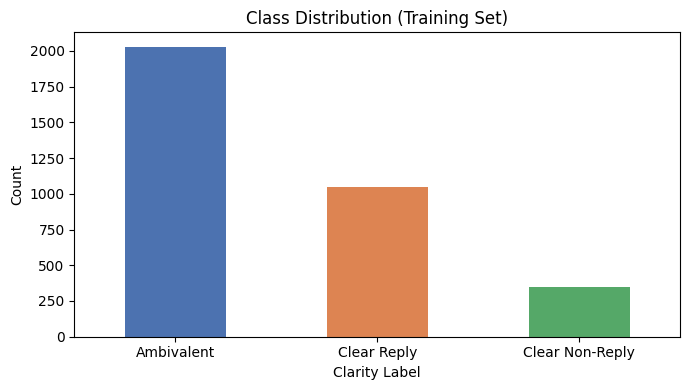

In [7]:
# Class distribution
print("=== Class Distribution (Training Set) ===")
print(df_train_full['clarity_label'].value_counts())
print()
print(df_train_full['clarity_label'].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
df_train_full['clarity_label'].value_counts().plot(
    kind='bar', ax=ax, color=['#4c72b0', '#dd8452', '#55a868']
)
ax.set_title('Class Distribution (Training Set)')
ax.set_xlabel('Clarity Label')
ax.set_ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('/kaggle/working/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

=== Question Length (characters) ===
count    3424.0
mean       84.7
std        52.0
min         3.0
25%        47.0
50%        74.0
75%       110.0
max       464.0
Name: question_len, dtype: float64

=== Answer Length (characters) ===
count     3424.0
mean      1659.9
std       1730.0
min          3.0
25%        309.8
50%       1155.5
75%       2488.5
max      12102.0
Name: answer_len, dtype: float64


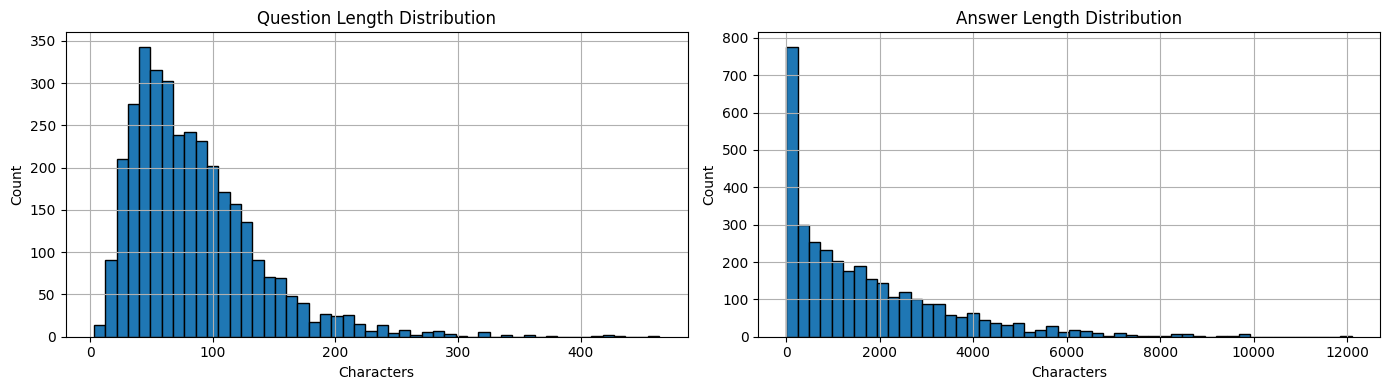

In [8]:
# Text length analysis
df_train_full['question_len'] = df_train_full['question'].astype(str).apply(len)
df_train_full['answer_len'] = df_train_full['interview_answer'].astype(str).apply(len)

print("=== Question Length (characters) ===")
print(df_train_full['question_len'].describe().round(1))
print("\n=== Answer Length (characters) ===")
print(df_train_full['answer_len'].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_train_full['question_len'].hist(bins=50, ax=axes[0], edgecolor='black')
axes[0].set_title('Question Length Distribution')
axes[0].set_xlabel('Characters')
axes[0].set_ylabel('Count')
df_train_full['answer_len'].hist(bins=50, ax=axes[1], edgecolor='black')
axes[1].set_title('Answer Length Distribution')
axes[1].set_xlabel('Characters')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.savefig('/kaggle/working/text_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.2. Label Encoding

In [9]:
label2id = {'Clear Reply': 0, 'Ambivalent': 1, 'Clear Non-Reply': 2}
id2label = {v: k for k, v in label2id.items()}

df_train_full['label'] = df_train_full['clarity_label'].map(label2id)

print("Label mapping:", label2id)
print("\nLabel counts:")
print(df_train_full['label'].value_counts().sort_index().rename(id2label))

Label mapping: {'Clear Reply': 0, 'Ambivalent': 1, 'Clear Non-Reply': 2}

Label counts:
label
Clear Reply        1045
Ambivalent         2028
Clear Non-Reply     351
Name: count, dtype: int64


## 2.3. Train / Validation Split

We use a stratified 85/15 split to preserve class proportions.

In [10]:
df_train, df_val = train_test_split(
    df_train_full,
    test_size=0.15,
    random_state=seed_val,
    stratify=df_train_full['label'],
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

print(f'{len(df_train):>5,} training samples')
print(f'{len(df_val):>5,} validation samples')
print("\nTraining label distribution:")
print(df_train['clarity_label'].value_counts())
print("\nValidation label distribution:")
print(df_val['clarity_label'].value_counts())

2,910 training samples
  514 validation samples

Training label distribution:
clarity_label
Ambivalent         1724
Clear Reply         888
Clear Non-Reply     298
Name: count, dtype: int64

Validation label distribution:
clarity_label
Ambivalent         304
Clear Reply        157
Clear Non-Reply     53
Name: count, dtype: int64


# 3. Few-Shot Example Pool

We reserve a small, balanced pool of labeled examples from the training set to use as demonstrations in few-shot and CoT prompting. These examples are selected to cover all three classes and are excluded from the validation evaluation to avoid leakage.

We select 1 example per class (3 total) by choosing the shortest answer for each class.

In [11]:
# Select 1 example per class — the one with the shortest answer
# Shorter = cleaner signal, less noise in the prompt context

demo_examples = []
for label_id in [0, 1, 2]:
    subset = df_train[df_train['label'] == label_id].copy()
    subset['a_len'] = subset['interview_answer'].astype(str).apply(len)
    chosen = subset.nsmallest(1, 'a_len')
    demo_examples.append(chosen)

demo_df = pd.concat(demo_examples).reset_index(drop=True)
print("Demonstration pool (1 per class, shortest answer):")
for _, row in demo_df.iterrows():
    print(f"  [{row['clarity_label']}] {len(str(row['interview_answer']))} chars — Q: {str(row['question'])[:60]}")

Demonstration pool (1 per class, shortest answer):
  [Clear Reply] 3 chars — Q: Does that include reducing military capabilities?
  [Ambivalent] 3 chars — Q: What assurances are you willing to give to Kim Jong Un?
  [Clear Non-Reply] 5 chars — Q: Is there a transcript of your conversation?


# 4. Prompt Construction

## Label Definitions (used in all prompts)

- **Clear Reply**: The politician directly addresses and answers the question, even if the answer is long, political, or self-serving. If the content of the response is on-topic and responsive, it is a Clear Reply.
- **Ambivalent**: The answer touches on the topic but is vague, hedging, or only partially responsive. The politician neither fully answers nor fully avoids.
- **Clear Non-Reply**: The politician completely deflects, changes the subject, refuses to answer, or says something entirely unrelated to what was asked. Signs include: talking about a completely different topic, answering a question that was not asked, saying they cannot comment, or giving only procedural/logistical responses with no substantive content.

## Prompt Formats

We implement three strategies:

1. **Zero-Shot**: Task description + label definitions + the instance to classify. No examples.
2. **Few-Shot**: Task description + labeled demonstration examples (one per class) + the instance.
3. **Chain-of-Thought (CoT)**: Task description + instruction to reason step-by-step before labeling + the instance.

All prompts use the Qwen chat template via `apply_chat_template` and instruct the model to output **only** the label string.

In [12]:
def preprocess_answer(text, max_chars=600):
    """
    Clean transcript noise and truncate. Applied to ALL answers —
    validation instances, test instances, and demonstration examples.
    """
    text = str(text)

    # 1. Remove bracketed content: speaker IDs, stage directions, empty brackets
    # e.g. [Kelly O'Donnell, NBC News], [], [laughter], [inaudible]
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'\(.*?\)', '', text)
    
    # 2. Fix run-together words caused by missing spaces in transcription
    # e.g. "theI am" -> "the I am", "thatI" -> "that I"
    text = re.sub(r'([a-z])([A-Z])', r'\1 \2', text)

    # 3. Remove em-dash interrupted speech at word boundaries
    # e.g. "The—" -> "The", "we're—" -> "we're"
    text = re.sub(r'(\w)—\s*$', r'\1', text, flags=re.MULTILINE)
    text = re.sub(r'(\w)—(\s)', r'\1\2', text)

    # 4. Strip filler openers that add no signal
    # These appear at the start of many presidential press conference answers
    filler = r'^(Oh\.\s*|Well,?\s*|Look,?\s*|So,?\s*|Okay,?\s*|Yes\.\s*|No\.\s*|Right\.\s*|Sure\.\s*|I mean,?\s*|You know,?\s*|Listen,?\s*)+'
    text = re.sub(filler, '', text.strip(), flags=re.IGNORECASE)

    # 5. Collapse multiple spaces and newlines
    text = re.sub(r'\s+', ' ', text).strip()

    # 6. Head + tail truncation
    if len(text) <= max_chars:
        return text
    half = max_chars // 2
    return text[:half] + " [...] " + text[-half:]


LABEL_DEFS = """Label definitions:
- Clear Reply: The politician directly addresses and answers the question, even if the answer is long, political, or self-serving. If the content of the response is on-topic and responsive, it is a Clear Reply.
- Ambivalent: The answer touches on the topic but is vague, hedging, or only partially responsive. The politician neither fully answers nor fully avoids.
- Clear Non-Reply: The politician completely deflects, changes the subject, refuses to answer, or says something entirely unrelated to what was asked. Signs of Clear Non-Reply: the politician talks about a completely different topic, answers a question that was not asked, says they cannot comment, or gives only procedural/logistical responses with no substantive content.

IMPORTANT: Do not confuse a long or opinionated answer with evasion. A verbose partisan answer that stays on-topic is a Clear Reply. Focus only on whether the question's core topic is addressed."""

VALID_LABELS = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]


def build_zero_shot_messages(question, answer):
    answer = preprocess_answer(answer)
    system = (
        "You are an expert political discourse analyst. "
        "Your task is to classify the clarity of a politician's answer to a journalist's question.\n\n"
        + LABEL_DEFS
        + "\n\nYour response must be EXACTLY one of these three labels, with no other text:\n"
        "1. Clear Reply\n"
        "2. Ambivalent\n"
        "3. Clear Non-Reply\n\n"
        "Do not explain. Do not add punctuation. Output only the label."
    )
    user = f"Question: {question}\n\nAnswer: {answer}\n\nLabel:"
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]
    
def build_few_shot_messages(question, answer, demo_df, n_per_class=2):
    answer = preprocess_answer(answer)
    system = (
        "You are an expert political discourse analyst. "
        "Your task is to classify the clarity of a politician's answer to a journalist's question.\n\n"
        + LABEL_DEFS
        + "\n\nYour response must be EXACTLY one of these three labels, with no other text:\n"
        "1. Clear Reply\n"
        "2. Ambivalent\n"
        "3. Clear Non-Reply\n\n"
        "Do not explain. Do not add punctuation. Output only the label."
    )
    demos = []
    for label_id in [0, 1, 2]:
        subset = demo_df[demo_df['label'] == label_id].head(n_per_class)
        for _, row in subset.iterrows():
            demos.append(
                f"Question: {row['question']}\n"
                f"Answer: {preprocess_answer(row['interview_answer'], max_chars=200)}\n"
                f"Label: {row['clarity_label']}"
            )
    demo_block = "\n\n---\n\n".join(demos)
    user = (
        f"Here are labeled examples:\n\n{demo_block}\n\n---\n\n"
        f"Now classify the following:\n\nQuestion: {question}\n\nAnswer: {answer}\n\nLabel:"
    )
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]

def build_cot_messages(question, answer):
    answer = preprocess_answer(answer)
    system = (
        "You are an expert political discourse analyst. "
        "Your task is to classify the clarity of a politician's answer to a journalist's question.\n\n"
        + LABEL_DEFS
        + "\n\nKey boundary rule: If the politician mentions the topic of the question but gives no "
        "substantive information or commitment, that is Ambivalent — not Clear Non-Reply. "
        "Clear Non-Reply is reserved for answers that ignore the question topic entirely.\n\n"
        "Analyze in exactly these steps:\n"
        "1. TOPIC OF QUESTION: State the specific topic the journalist is asking about.\n"
        "2. TOPIC OF ANSWER: State what the politician actually discusses.\n"
        "3. OVERLAP: Do the topics match? Is the question fully answered, partially addressed, or ignored?\n"
        "4. VERDICT: Choose exactly one label based on the overlap.\n\n"
        "End your response with this exact line:\n"
        "Label: <one of: Clear Reply, Ambivalent, Clear Non-Reply>"
    )
    user = f"Question: {question}\n\nAnswer: {answer}"
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]
    

print("Prompt builders defined.")

Prompt builders defined.


# 5. Output Parsing

Qwen3.5 is an instruction-tuned model; however, it may still produce verbose output especially for CoT prompting. We need a robust parser that extracts the label from any response format.

The parser uses a priority cascade:
1. Look for `Label: <label>` pattern (CoT output).
2. Look for an exact label string anywhere in the output.
3. Fall back to `"Ambivalent"` (most frequent hedging class) for invalid outputs. Invalid output rates are logged separately by the caller.

In [13]:
def parse_label(text, strategy='zero_shot'):
    if not text:
        return "Ambivalent"

    raw = text.strip()

    # For CoT: only extract the label from the explicit "Label: X" line
    # Do NOT do substring matching on reasoning text — it contains all three
    # label words naturally in sentences like "does not give a clear reply"
    if 'cot' in strategy:
        # Priority 1: find "Label: X" pattern anywhere in the text
        match = re.search(
            r'Label\s*:\s*(Clear Non-Reply|Clear Reply|Ambivalent)',
            raw, re.IGNORECASE
        )
        if match:
            val = match.group(1).strip()
            for v in VALID_LABELS:
                if val.lower() == v.lower():
                    return v
        # Priority 2: last non-empty line that is exactly a label
        lines = [l.strip() for l in raw.split('\n') if l.strip()]
        for line in reversed(lines):
            ll = line.strip(' ."\':-*#')
            if ll.lower() == 'clear non-reply':
                return 'Clear Non-Reply'
            if ll.lower() == 'clear reply':
                return 'Clear Reply'
            if ll.lower() == 'ambivalent':
                return 'Ambivalent'
        return "Ambivalent"

    # For zero/few-shot: the model outputs only the label, so just find it
    for label in VALID_LABELS:
        if raw.startswith(label):
            return label
    # Check longer labels first to avoid "Clear Reply" matching inside "Clear Non-Reply"
    for label in sorted(VALID_LABELS, key=len, reverse=True):
        if label.lower() in raw.lower():
            return label
    return "Ambivalent"


# Quick tests
assert parse_label("Label: Clear Reply") == "Clear Reply"
assert parse_label("Label: Clear Non-Reply", strategy='cot') == "Clear Non-Reply"
assert parse_label("The politician does not give a clear reply to the question.\nLabel: Ambivalent", strategy='cot') == "Ambivalent"
assert parse_label("The answer avoids the topic entirely.\nLabel: Clear Non-Reply", strategy='cot') == "Clear Non-Reply"
assert parse_label("Clear Reply") == "Clear Reply"
assert parse_label("gibberish xyz") == "Ambivalent"
print("Parser tests passed.")

Parser tests passed.


# 6. Inference Pipeline

The inference pipeline consists of two functions defined in this cell:
- `load_model`: loads the tokenizer and model with 4-bit quantization (falling back to float16 if unavailable).
- `run_inference`: applies the chat template, runs batched greedy decoding, and returns decoded outputs.
- Greedy decoding (`do_sample=False`, `temperature=1.0`) for reproducibility.
- `max_new_tokens=16` for zero-shot/few-shot (label only), `250` for CoT (reasoning + label).

In [14]:
def load_model(model_name):
    print(f"Loading {model_name}...")
    tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
    tokenizer.padding_side = 'left'
    tokenizer.truncation_side = 'left'
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    try:
        from transformers import BitsAndBytesConfig
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_use_double_quant=True,
            bnb_4bit_quant_type='nf4',
            bnb_4bit_compute_dtype=torch.float16,
        )
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            quantization_config=bnb_config,
            device_map="auto",
            trust_remote_code=True,
        )
        print(f"  Loaded with 4-bit quantization.")
    except Exception as e:
        print(f"  4-bit failed ({e}), loading in float16...")
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            torch_dtype=torch.float16,
            device_map="auto",
            trust_remote_code=True,
        )

    model.eval()
    print(f"  Parameters: {sum(p.numel() for p in model.parameters())/1e6:.0f}M")
    return tokenizer, model


def run_inference(tokenizer, model, messages_list, max_new_tokens=16, batch_size=4):
    all_outputs = []
    for i in range(0, len(messages_list), batch_size):
        batch_messages = messages_list[i:i + batch_size]
        batch_texts = []
        for messages in batch_messages:
            text = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True,
                enable_thinking=False,
            )
            batch_texts.append(text)

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=2048,
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                temperature=1.0,
                pad_token_id=tokenizer.pad_token_id,
            )

        for j, output in enumerate(outputs):
            input_len = inputs['input_ids'][j].shape[0]
            generated = output[input_len:]
            decoded = tokenizer.decode(generated, skip_special_tokens=True)
            all_outputs.append(decoded)

        if (i // batch_size + 1) % 10 == 0:
            print(f"  Processed {i + len(batch_messages)}/{len(messages_list)} samples...")

    return all_outputs


def evaluate_predictions(true_labels, pred_labels, label_names=None):
    if label_names is None:
        label_names = VALID_LABELS
    print("=== Classification Report ===\n")
    print(classification_report(
        true_labels, pred_labels,
        labels=VALID_LABELS,
        target_names=VALID_LABELS,
        digits=4
    ))
    acc  = accuracy_score(true_labels, pred_labels)
    f1w  = f1_score(true_labels, pred_labels, average='weighted')
    f1m  = f1_score(true_labels, pred_labels, average='macro')
    prec = precision_score(true_labels, pred_labels, average='macro', zero_division=0)
    rec  = recall_score(true_labels, pred_labels, average='macro', zero_division=0)
    print(f"Accuracy:          {acc:.4f}")
    print(f"F1 (weighted):     {f1w:.4f}")
    print(f"F1 (macro):        {f1m:.4f}")
    print(f"Precision (macro): {prec:.4f}")
    print(f"Recall (macro):    {rec:.4f}")
    return {'accuracy': acc, 'f1_weighted': f1w, 'f1_macro': f1m,
            'precision_macro': prec, 'recall_macro': rec}

print("Inference pipeline defined.")

Inference pipeline defined.


# 7. Experiments

We evaluate all combinations of:
- **Models**: Qwen3.5-0.8B, Qwen3.5-2B, Qwen3.5-4B
- **Strategies**: zero-shot, few-shot, CoT

We run on the validation set (15% of training data). Results are stored in `all_results` for downstream comparison plots.

In [15]:
val_questions = df_val['question'].tolist()
val_answers   = df_val['interview_answer'].tolist()
val_true      = df_val['clarity_label'].tolist()

from sklearn.model_selection import train_test_split as _tts

_, val_sub = _tts(
    df_val,
    test_size=250,
    random_state=seed_val,
    stratify=df_val['label'],
)
val_sub = val_sub.reset_index(drop=True)

val_questions_sub = val_sub['question'].tolist()
val_answers_sub   = val_sub['interview_answer'].tolist()
val_true_sub      = val_sub['clarity_label'].tolist()

print(f"Full validation set:    {len(val_true)} samples")
print(f"Subset for experiments: {len(val_true_sub)} samples")
print("Subset label distribution:")
print(val_sub['clarity_label'].value_counts())

print("\nBuilding prompt message lists...")

val_messages = {
    'zero_shot': [build_zero_shot_messages(q, a)
                  for q, a in zip(val_questions_sub, val_answers_sub)],
    'few_shot':  [build_few_shot_messages(q, a, demo_df, n_per_class=2)
                  for q, a in zip(val_questions_sub, val_answers_sub)],
    'cot':       [build_cot_messages(q, a)
                  for q, a in zip(val_questions_sub, val_answers_sub)],
}

val_messages_full = {
    'zero_shot': [build_zero_shot_messages(q, a)
                  for q, a in zip(val_questions, val_answers)],
    'few_shot':  [build_few_shot_messages(q, a, demo_df, n_per_class=2)
                  for q, a in zip(val_questions, val_answers)],
    'cot':       [build_cot_messages(q, a)
                  for q, a in zip(val_questions, val_answers)],
}

for strat, msgs in val_messages.items():
    print(f"  {strat}: {len(msgs)} prompts (subset)")

Full validation set:    514 samples
Subset for experiments: 250 samples
Subset label distribution:
clarity_label
Ambivalent         148
Clear Reply         76
Clear Non-Reply     26
Name: count, dtype: int64

Building prompt message lists...
  zero_shot: 250 prompts (subset)
  few_shot: 250 prompts (subset)
  cot: 250 prompts (subset)


## 7.1. Run All Models and Strategies

Each model is loaded, all 3 strategies are evaluated, then the model is deleted from GPU memory before loading the next one.

In [16]:
import gc

MODEL_NAMES = [
    "Qwen/Qwen3.5-0.8B",
    "Qwen/Qwen3.5-2B",
    "Qwen/Qwen3.5-4B",
]

STRATEGIES_PER_MODEL = {
    'Qwen3.5-0.8B': {
        'zero_shot':    {'max_new_tokens': 16,  'batch_size': 16},
        'few_shot':     {'max_new_tokens': 16,  'batch_size': 16},
        'cot':          {'max_new_tokens': 250, 'batch_size': 8},
    },
    'Qwen3.5-2B': {
        'zero_shot':    {'max_new_tokens': 16,  'batch_size': 8},
        'few_shot':     {'max_new_tokens': 16,  'batch_size': 8},
        'cot':          {'max_new_tokens': 250, 'batch_size': 4},
    },
    'Qwen3.5-4B': {
        'zero_shot':    {'max_new_tokens': 16,  'batch_size': 8},
        'few_shot':     {'max_new_tokens': 16,  'batch_size': 8},
        'cot':          {'max_new_tokens': 250, 'batch_size': 4},
    },
}

all_results = {}
all_preds   = {}

# We'll store the best model's tokenizer and model here instead of reloading
best_tokenizer_saved = None
best_model_saved     = None
best_model_name_saved = None

for model_name in MODEL_NAMES:
    model_short = model_name.split('/')[-1]
    tokenizer, model = load_model(model_name)
    strategies = STRATEGIES_PER_MODEL[model_short]

    for strat, gen_kwargs in strategies.items():
        print(f"\n--- {model_short} | {strat} ---")
        torch.cuda.empty_cache()

        raw_outputs = run_inference(
            tokenizer, model,
            val_messages[strat],
            max_new_tokens=gen_kwargs['max_new_tokens'],
            batch_size=gen_kwargs['batch_size'],
        )

        pred_labels = [parse_label(o, strategy=strat) for o in raw_outputs]
        def is_invalid_output(raw_text):
            """True only when the parser had to fall back — no valid label found in output."""
            t = raw_text.strip().lower()
            return not any(label.lower() in t for label in VALID_LABELS)
        
        invalid_count = sum(is_invalid_output(o) for o in raw_outputs)
        print(f"  Invalid outputs (fallback used): {invalid_count}/{len(raw_outputs)} "
              f"({100*invalid_count/len(raw_outputs):.1f}%)")
        metrics = evaluate_predictions(val_true_sub, pred_labels)
        all_results[(model_short, strat)] = metrics
        all_preds[(model_short, strat)]   = pred_labels

    # Determine if this model is the best so far — if so, keep it alive
    current_best = pd.DataFrame([
        {'Model': m, 'Strategy': s, 'F1 Weighted': v['f1_weighted']}
        for (m, s), v in all_results.items()
    ]).sort_values('F1 Weighted', ascending=False).iloc[0]

    if current_best['Model'] == model_short:
        # This model is currently the best — hold onto it
        if best_model_saved is not None:
            del best_model_saved, best_tokenizer_saved
            gc.collect()
            torch.cuda.empty_cache()
        best_model_saved      = model
        best_tokenizer_saved  = tokenizer
        best_model_name_saved = model_name
        print(f"\nKeeping {model_short} alive (currently best).")
    else:
        del model, tokenizer
        gc.collect()
        torch.cuda.empty_cache()
        print(f"\nFreed GPU memory after {model_short}.")

# Identify final best combo
best_row_tmp = pd.DataFrame([
    {'Model': m, 'Strategy': s, 'F1 Weighted': v['f1_weighted']}
    for (m, s), v in all_results.items()
]).sort_values('F1 Weighted', ascending=False).iloc[0]

best_model_tmp    = best_row_tmp['Model']
best_strategy_tmp = best_row_tmp['Strategy']
print(f"\nBest combo from subset: {best_model_tmp} + {best_strategy_tmp}")

# If the best model was not the last one processed, reload it
if best_model_name_saved != f"Qwen/{best_model_tmp}":
    for _var in ['best_model_saved', 'best_tokenizer_saved']:
        if _var in globals() and globals()[_var] is not None:
            del globals()[_var]
    gc.collect()
    torch.cuda.empty_cache()
    best_tokenizer_saved, best_model_saved = load_model(f"Qwen/{best_model_tmp}")

print("Running full validation set on best combo...")
full_bs      = STRATEGIES_PER_MODEL[best_model_tmp][best_strategy_tmp]['batch_size']
full_max_new = STRATEGIES_PER_MODEL[best_model_tmp][best_strategy_tmp]['max_new_tokens']

torch.cuda.empty_cache()
raw_full   = run_inference(
    best_tokenizer_saved, best_model_saved,
    val_messages_full[best_strategy_tmp],
    max_new_tokens=full_max_new,
    batch_size=full_bs,
)
preds_full = [parse_label(o, strategy=best_strategy_tmp) for o in raw_full]
print(f"\nFull validation results for {best_model_tmp} + {best_strategy_tmp}:")
metrics_full     = evaluate_predictions(val_true, preds_full)
all_results_full = {(best_model_tmp, best_strategy_tmp): metrics_full}
all_preds_full   = {(best_model_tmp, best_strategy_tmp): preds_full}

print("\nAll experiments complete.")

Loading Qwen/Qwen3.5-0.8B...


config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.35M [00:00<?, ?B/s]

...

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

  Loaded with 4-bit quantization.
  Parameters: 2421M

--- Qwen3.5-4B | zero_shot ---
  Processed 80/250 samples...
  Processed 160/250 samples...
  Processed 240/250 samples...
  Invalid outputs (fallback used): 0/250 (0.0%)
=== Classification Report ===

                 precision    recall  f1-score   support

    Clear Reply     0.4948    0.6316    0.5549        76
     Ambivalent     0.2000    0.0068    0.0131       148
Clear Non-Reply     0.1486    0.8462    0.2529        26

       accuracy                         0.2840       250
      macro avg     0.2812    0.4948    0.2736       250
   weighted avg     0.2843    0.2840    0.2027       250

Accuracy:          0.2840
F1 (weighted):     0.2027
F1 (macro):        0.2736
Precision (macro): 0.2812
Recall (macro):    0.4948

--- Qwen3.5-4B | few_shot ---
  Processed 80/250 samples...
  Processed 160/250 samples...
  Processed 240/250 samples...
  Invalid outputs (fallback used): 0/250 (0.0%)
=== Classification Report ===

         

# 8. Results Summary Table

In [17]:
rows = []
for (model_short, strat), metrics in all_results.items():
    rows.append({
        'Model':       model_short,
        'Strategy':    strat,
        'Accuracy':    round(metrics['accuracy'], 4),
        'F1 Weighted': round(metrics['f1_weighted'], 4),
        'F1 Macro':    round(metrics['f1_macro'], 4),
        'Prec Macro':  round(metrics['precision_macro'], 4),
        'Rec Macro':   round(metrics['recall_macro'], 4),
    })

results_df = pd.DataFrame(rows)
results_df = results_df.sort_values(['Model', 'Strategy']).reset_index(drop=True)
pd.options.display.precision = 4
print(results_df.to_string(index=False))

       Model  Strategy  Accuracy  F1 Weighted  F1 Macro  Prec Macro  Rec Macro
Qwen3.5-0.8B       cot     0.332       0.2163    0.2709      0.4442     0.3934
Qwen3.5-0.8B  few_shot     0.504       0.4683    0.3113      0.2989     0.3286
Qwen3.5-0.8B zero_shot     0.592       0.4473    0.2560      0.3642     0.3355
  Qwen3.5-2B       cot     0.612       0.5208    0.3342      0.4167     0.3702
  Qwen3.5-2B  few_shot     0.312       0.1862    0.2687      0.3544     0.4496
  Qwen3.5-2B zero_shot     0.328       0.2218    0.2946      0.3790     0.4755
  Qwen3.5-4B       cot     0.476       0.5044    0.4389      0.4563     0.4782
  Qwen3.5-4B  few_shot     0.300       0.2083    0.2687      0.2776     0.4491
  Qwen3.5-4B zero_shot     0.284       0.2027    0.2736      0.2812     0.4948


# 9. Comparison Plots
## 9.1. F1 (Weighted) Heatmap — Model vs Strategy

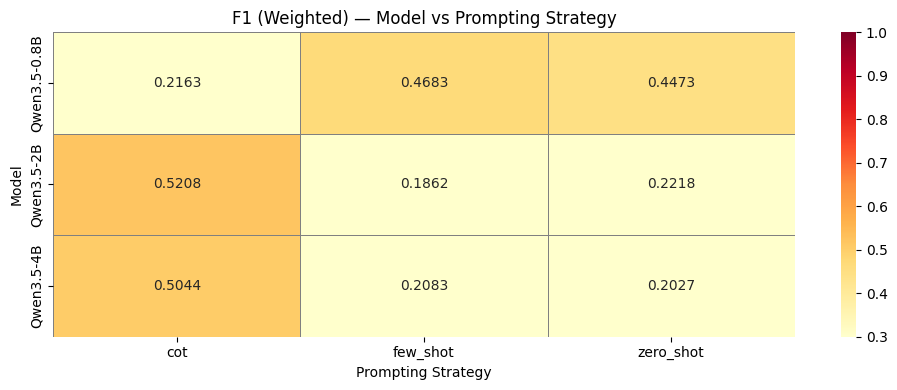

In [18]:
pivot_f1w = results_df.pivot(index='Model', columns='Strategy', values='F1 Weighted')

plt.figure(figsize=(10, 4))
sns.heatmap(
    pivot_f1w, annot=True, fmt='.4f', cmap='YlOrRd',
    linewidths=0.5, linecolor='gray', vmin=0.3, vmax=1.0
)
plt.title('F1 (Weighted) — Model vs Prompting Strategy')
plt.xlabel('Prompting Strategy')
plt.ylabel('Model')
plt.tight_layout()
plt.savefig('/kaggle/working/heatmap_f1_weighted.png', dpi=150, bbox_inches='tight')
plt.show()

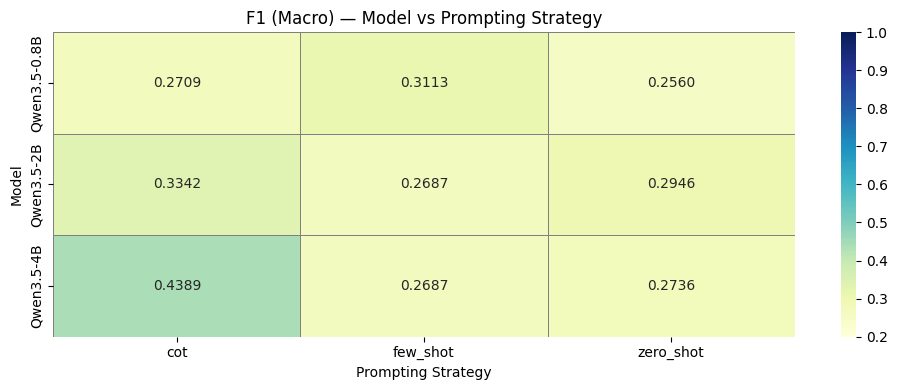

In [19]:
# F1 Macro heatmap
pivot_f1m = results_df.pivot(index='Model', columns='Strategy', values='F1 Macro')

plt.figure(figsize=(10, 4))
sns.heatmap(
    pivot_f1m, annot=True, fmt='.4f', cmap='YlGnBu',
    linewidths=0.5, linecolor='gray', vmin=0.2, vmax=1.0
)
plt.title('F1 (Macro) — Model vs Prompting Strategy')
plt.xlabel('Prompting Strategy')
plt.ylabel('Model')
plt.tight_layout()
plt.savefig('/kaggle/working/heatmap_f1_macro.png', dpi=150, bbox_inches='tight')
plt.show()

## 9.2. Grouped Bar Chart — F1 Weighted by Strategy and Model Size

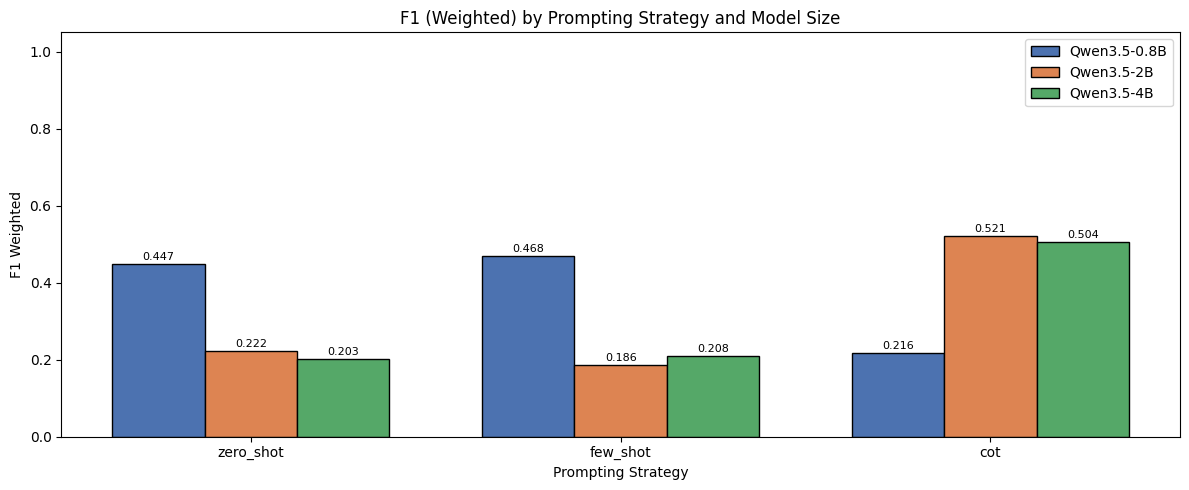

In [20]:
strategies_order = ['zero_shot', 'few_shot', 'cot'] 
models_order = ['Qwen3.5-0.8B', 'Qwen3.5-2B', 'Qwen3.5-4B']
colors = ['#4c72b0', '#dd8452', '#55a868']

x = np.arange(len(strategies_order))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 5))

for i, (model, color) in enumerate(zip(models_order, colors)):
    vals = [
        all_results.get((model, s), {}).get('f1_weighted', 0)
        for s in strategies_order
    ]
    bars = ax.bar(x + i * width, vals, width, label=model, color=color, edgecolor='black')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                f'{v:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_title('F1 (Weighted) by Prompting Strategy and Model Size')
ax.set_xlabel('Prompting Strategy')
ax.set_ylabel('F1 Weighted')
ax.set_xticks(x + width)
ax.set_xticklabels(strategies_order)
ax.legend()
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig('/kaggle/working/grouped_bar_f1_weighted.png', dpi=150, bbox_inches='tight')
plt.show()

## 9.3. Performance Scaling with Model Size

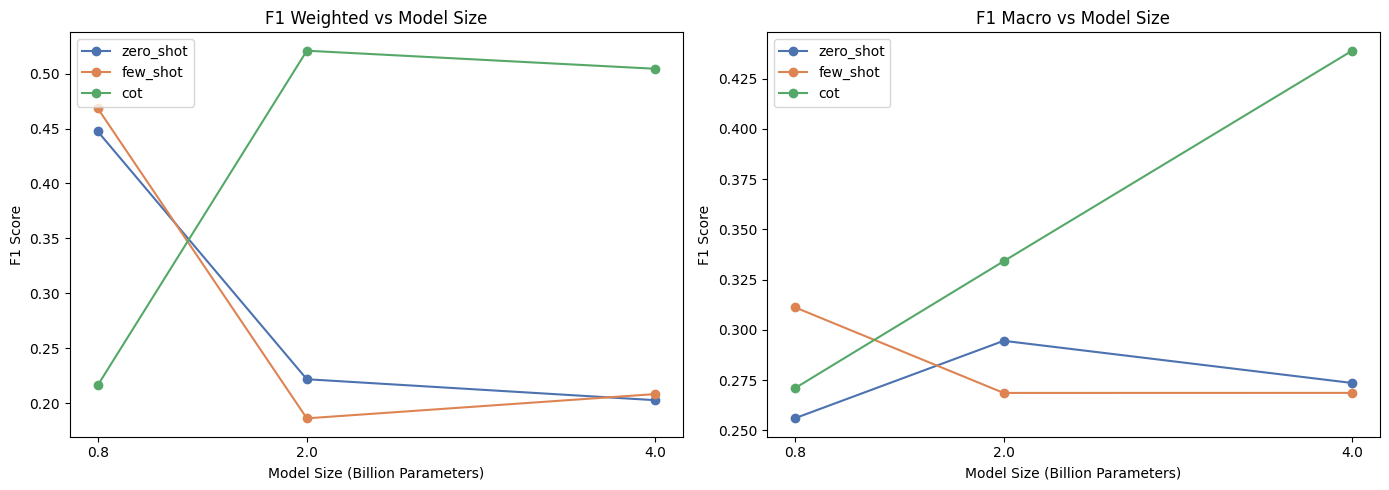

In [21]:
param_counts = {'Qwen3.5-0.8B': 0.8, 'Qwen3.5-2B': 2.0, 'Qwen3.5-4B': 4.0}
strat_colors = {'zero_shot': '#4c72b0', 'few_shot': '#dd8452',
                'cot': '#55a868'}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for strat, color in strat_colors.items():
    xs = [param_counts[m] for m in models_order]
    ys_w = [all_results.get((m, strat), {}).get('f1_weighted', 0) for m in models_order]
    ys_m = [all_results.get((m, strat), {}).get('f1_macro', 0)    for m in models_order]
    axes[0].plot(xs, ys_w, marker='o', label=strat, color=color)
    axes[1].plot(xs, ys_m, marker='o', label=strat, color=color)

for ax, title in zip(axes, ['F1 Weighted vs Model Size', 'F1 Macro vs Model Size']):
    ax.set_xlabel('Model Size (Billion Parameters)')
    ax.set_ylabel('F1 Score')
    ax.set_title(title)
    ax.set_xticks([0.8, 2.0, 4.0])
    ax.legend()

plt.tight_layout()
plt.savefig('/kaggle/working/scaling_curve.png', dpi=150, bbox_inches='tight')
plt.show()

# 10. Error Analysis

We use the best-performing combination (identified from `results_df`) for detailed error analysis.

In [22]:
# Use the full-set predictions computed at the end of Cell 29
best_model    = best_model_tmp
best_strategy = best_strategy_tmp
best_preds    = preds_full       # predictions from the full val run

print(f"Best combination: {best_model} + {best_strategy}")
print(f"  F1 Weighted (full val): {metrics_full['f1_weighted']:.4f}")
print(f"  F1 Macro    (full val): {metrics_full['f1_macro']:.4f}")

Best combination: Qwen3.5-2B + cot
  F1 Weighted (full val): 0.5014
  F1 Macro    (full val): 0.3151


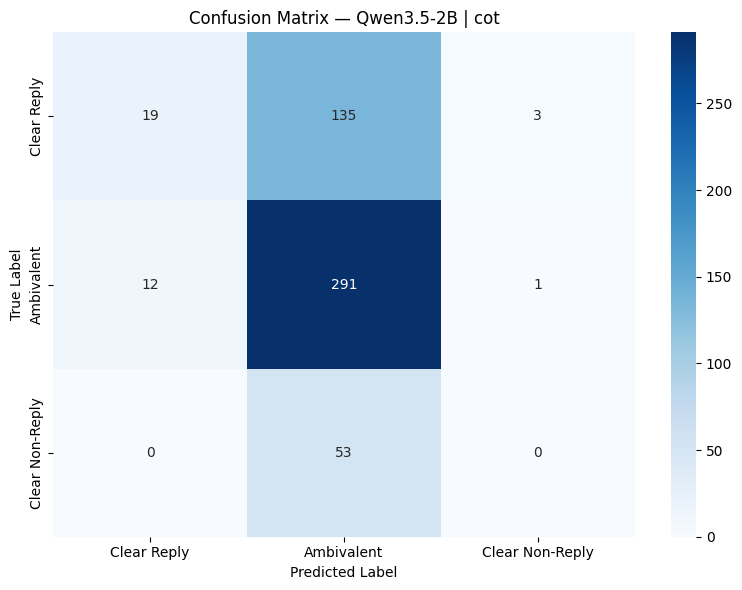

In [23]:
# Confusion matrix for the best model/strategy
cm = confusion_matrix(val_true, best_preds, labels=VALID_LABELS)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=VALID_LABELS, yticklabels=VALID_LABELS)
plt.title(f'Confusion Matrix — {best_model} | {best_strategy}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix_best.png', dpi=150, bbox_inches='tight')
plt.show()

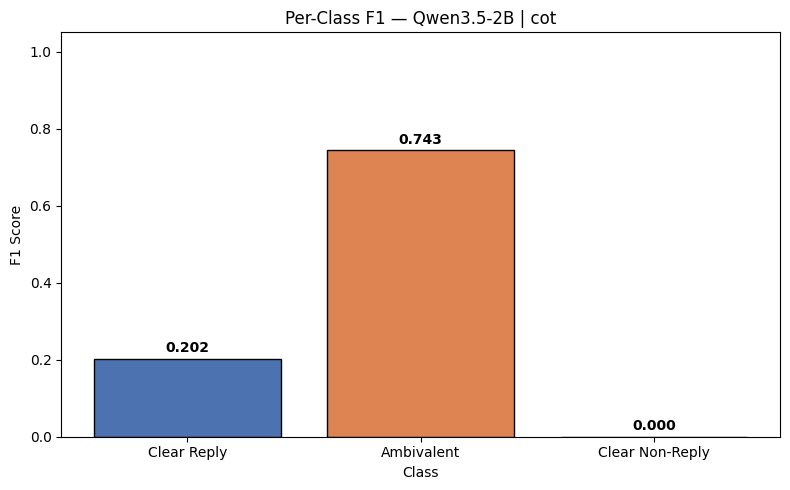

In [24]:
# Per-class F1 bar chart for best model/strategy
per_class_f1 = f1_score(val_true, best_preds, average=None, labels=VALID_LABELS)

plt.figure(figsize=(8, 5))
bars = plt.bar(VALID_LABELS, per_class_f1,
               color=['#4c72b0', '#dd8452', '#55a868'], edgecolor='black')
for bar, val in zip(bars, per_class_f1):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontweight='bold')
plt.title(f'Per-Class F1 — {best_model} | {best_strategy}')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.savefig('/kaggle/working/per_class_f1_best.png', dpi=150, bbox_inches='tight')
plt.show()

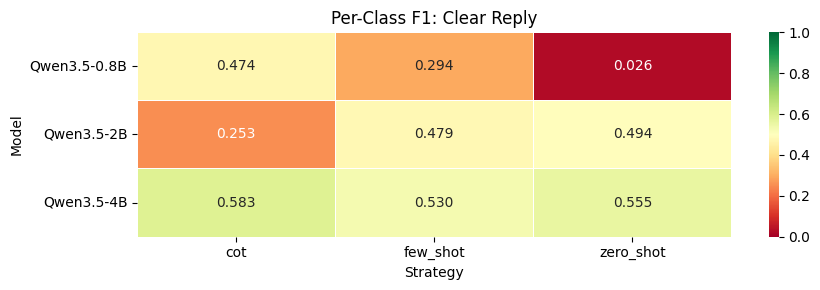

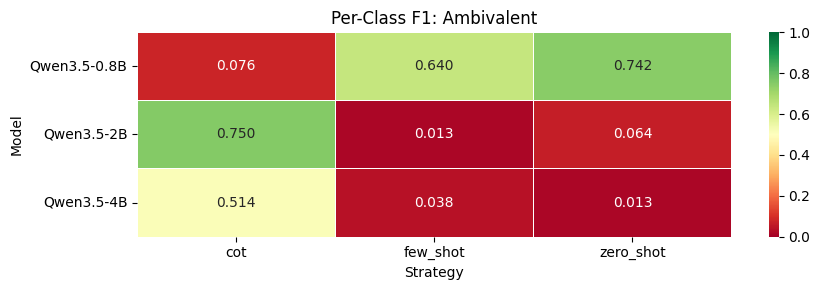

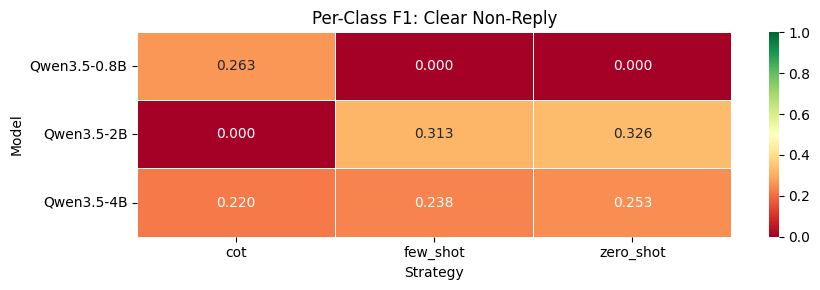

In [25]:
# Per-class F1 across ALL models and strategies (heatmap per class)
# all_preds contains subset (250) predictions, so use val_true_sub
for target_class in VALID_LABELS:
    class_f1s = {}
    for (model, strat), preds in all_preds.items():
        per_cls = f1_score(val_true_sub, preds, average=None, labels=VALID_LABELS,
                           zero_division=0)
        idx = VALID_LABELS.index(target_class)
        class_f1s[(model, strat)] = per_cls[idx]

    pivot = pd.Series(class_f1s).unstack()
    plt.figure(figsize=(9, 3))
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdYlGn',
                linewidths=0.5, vmin=0.0, vmax=1.0)
    plt.title(f'Per-Class F1: {target_class}')
    plt.xlabel('Strategy')
    plt.ylabel('Model')
    plt.tight_layout()
    fname = target_class.replace(' ', '_').lower()
    plt.savefig(f'/kaggle/working/per_class_{fname}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [26]:
# Build error dataframe for the best combination
val_results_df = pd.DataFrame({
    'question':        val_questions,
    'answer':          val_answers,
    'true_label':      val_true,
    'predicted_label': best_preds,
    'correct':         [t == p for t, p in zip(val_true, best_preds)],
})

errors = val_results_df[~val_results_df['correct']].copy()
print(f"Total validation samples: {len(val_results_df)}")
print(f"Misclassified:            {len(errors)}")
print(f"Error rate:               {len(errors)/len(val_results_df):.2%}")
print()
print("=== Errors by True Label ===")
print(errors['true_label'].value_counts())
print()
print("=== Confusion Pairs (True -> Predicted) ===")
print(errors.groupby(['true_label', 'predicted_label']).size().sort_values(ascending=False))

Total validation samples: 514
Misclassified:            204
Error rate:               39.69%

=== Errors by True Label ===
true_label
Clear Reply        138
Clear Non-Reply     53
Ambivalent          13
Name: count, dtype: int64

=== Confusion Pairs (True -> Predicted) ===
true_label       predicted_label
Clear Reply      Ambivalent         135
Clear Non-Reply  Ambivalent          53
Ambivalent       Clear Reply         12
Clear Reply      Clear Non-Reply      3
Ambivalent       Clear Non-Reply      1
dtype: int64


In [27]:
print("=" * 80)
print("SAMPLE MISCLASSIFIED EXAMPLES")
print("=" * 80)

for i, (_, row) in enumerate(errors.head(6).iterrows()):
    print(f"\n--- Example {i+1} ---")
    print(f"True: {row['true_label']}  |  Predicted: {row['predicted_label']}")
    print(f"Question: {str(row['question'])[:250]}")
    print(f"Answer:   {str(row['answer'])[:400]}")
    print("-" * 80)

SAMPLE MISCLASSIFIED EXAMPLES

--- Example 1 ---
True: Clear Reply  |  Predicted: Ambivalent
Question: Do you think it's time for tough U.N. sanctions with real teeth?
Answer:   As you know, we have been discussing this issue a lot at these press avails. Iran is constantly on the agenda at a press avail like this—or a press conference like this, and the reason why is, is because they continue to be defiant as to the demands of the free world. The world has spoken and said, no nuclear weapons programs. And yet they're constantly ignoring the demands.My view is that we need
--------------------------------------------------------------------------------

--- Example 2 ---
True: Clear Non-Reply  |  Predicted: Ambivalent
Question: What is the high watermark for unemployment?
Answer:   Well, I'm not suggesting that I have a crystal ball. Since you just threw back at us our last prognosis, let's not engage in another one.
----------------------------------------------------------------------

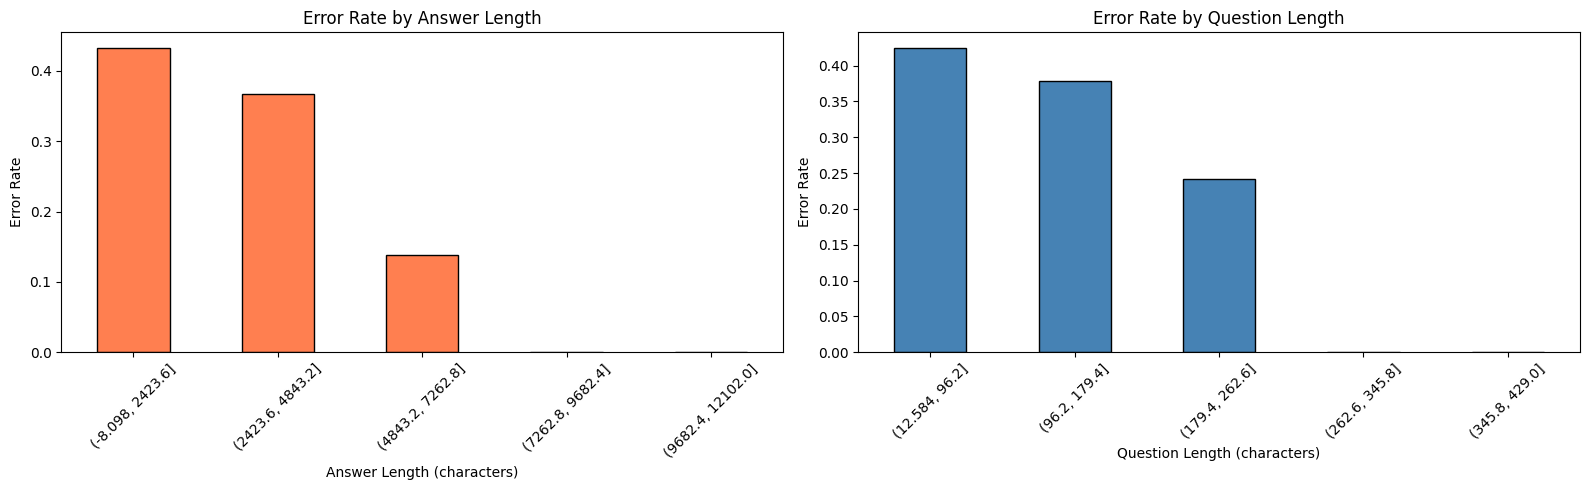

In [28]:
# Error rate by answer and question length
val_results_df['a_len'] = val_results_df['answer'].astype(str).apply(len)
val_results_df['q_len'] = val_results_df['question'].astype(str).apply(len)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

val_results_df['a_len_bin'] = pd.cut(val_results_df['a_len'], bins=5)
error_by_alen = val_results_df.groupby('a_len_bin', observed=True)['correct'].apply(
    lambda x: 1 - x.mean()
)
error_by_alen.plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Error Rate by Answer Length')
axes[0].set_xlabel('Answer Length (characters)')
axes[0].set_ylabel('Error Rate')
axes[0].tick_params(axis='x', rotation=45)

val_results_df['q_len_bin'] = pd.cut(val_results_df['q_len'], bins=5)
error_by_qlen = val_results_df.groupby('q_len_bin', observed=True)['correct'].apply(
    lambda x: 1 - x.mean()
)
error_by_qlen.plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
axes[1].set_title('Error Rate by Question Length')
axes[1].set_xlabel('Question Length (characters)')
axes[1].set_ylabel('Error Rate')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('/kaggle/working/error_rate_by_length.png', dpi=150, bbox_inches='tight')
plt.show()

## 10.1. Confusion Matrix Comparison Across All Strategies (Best Model)

We compare confusion matrices across the 3 strategies for the best-performing model size to understand how prompting strategy changes the failure mode.

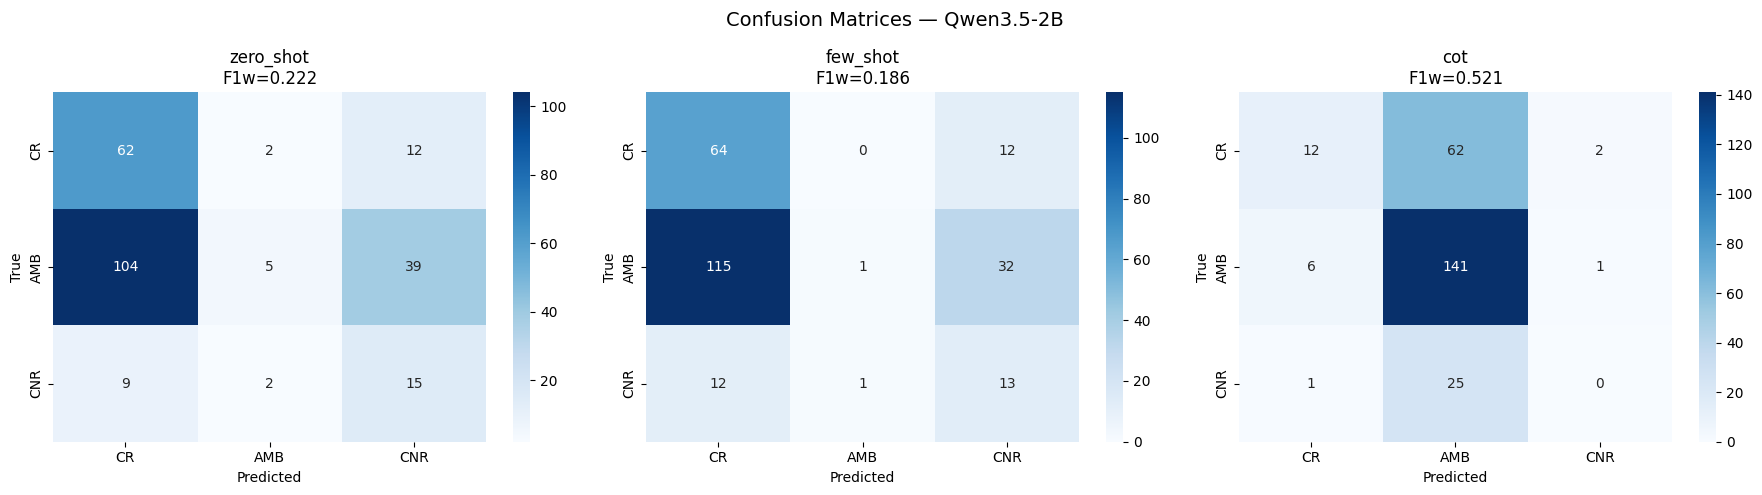

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, strat in zip(axes, ['zero_shot', 'few_shot', 'cot']):  
    preds = all_preds.get((best_model, strat), [])
    if not preds:
        ax.set_visible(False)
        continue
    # all_preds are subset predictions — use val_true_sub
    cm = confusion_matrix(val_true_sub, preds, labels=VALID_LABELS)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['CR', 'AMB', 'CNR'],
                yticklabels=['CR', 'AMB', 'CNR'], ax=ax)
    f1w = f1_score(val_true_sub, preds, average='weighted')
    ax.set_title(f'{strat}\nF1w={f1w:.3f}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.suptitle(f'Confusion Matrices — {best_model}', fontsize=14)
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrices_all_strategies.png', dpi=150, bbox_inches='tight')
plt.show()

# 11. Subgroup Analysis — Performance by Answer and Question Length

We bin the 250-sample validation subset by answer length into quartiles and compute F1 per bin for the best model/strategy. This reveals whether prompting-based models struggle more on longer or shorter answers.

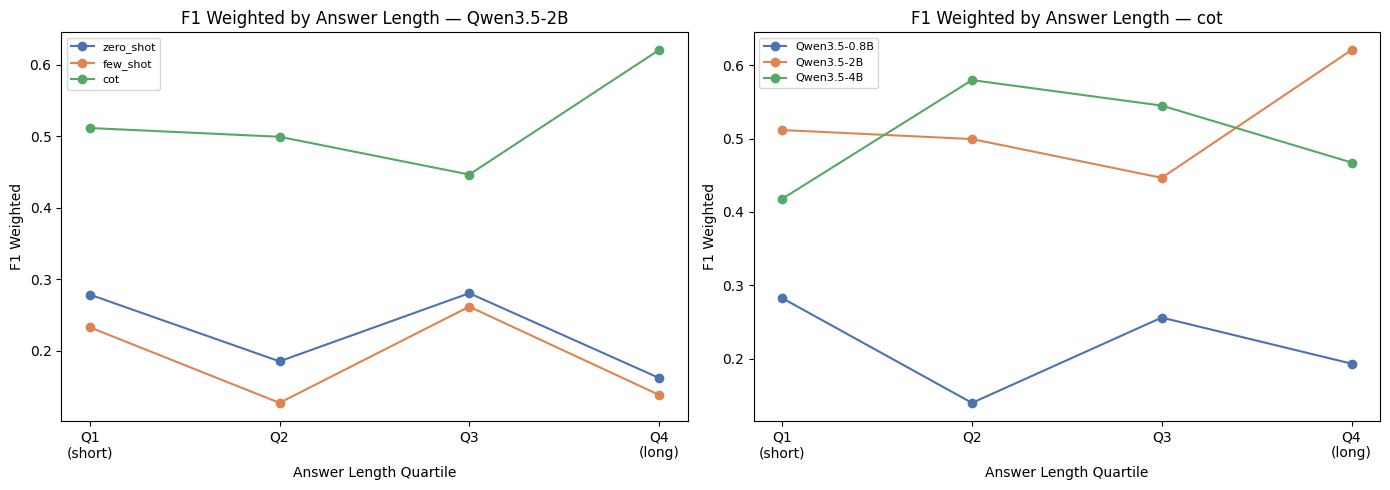

In [30]:
# Subgroup analysis uses the 250-sample validation subset (val_true_sub / val_messages)
# Use subset predictions for the best model/strategy if available,
# otherwise use first len(val_true_sub) elements of best_preds

subset_preds_for_best = all_preds.get(
    (best_model, best_strategy),
    best_preds[:len(val_true_sub)]
)

# Ensure lengths match — take the safe minimum
n = min(len(val_true_sub), len(subset_preds_for_best))

val_sub_results_df = pd.DataFrame({
    'question':        val_questions_sub[:n],
    'answer':          val_answers_sub[:n],
    'true_label':      val_true_sub[:n],
    'predicted_label': subset_preds_for_best[:n],
    'correct':         [t == p for t, p in zip(val_true_sub[:n], subset_preds_for_best[:n])],
})

val_sub_results_df['a_len'] = val_sub_results_df['answer'].astype(str).apply(len)
val_sub_results_df['a_len_quartile'] = pd.qcut(
    val_sub_results_df['a_len'], q=4,
    labels=['Q1\n(short)', 'Q2', 'Q3', 'Q4\n(long)']
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for strat, color in strat_colors.items():
    preds = all_preds.get((best_model, strat), [])
    if not preds:
        continue
    n_strat = min(len(val_sub_results_df), len(preds))
    val_sub_results_df['pred_tmp'] = preds[:n_strat]
    grp = val_sub_results_df.iloc[:n_strat].groupby('a_len_quartile', observed=True).apply(
        lambda df: f1_score(df['true_label'], df['pred_tmp'],
                            average='weighted', labels=VALID_LABELS, zero_division=0)
    )
    axes[0].plot(grp.index, grp.values, marker='o', label=strat, color=color)

axes[0].set_title(f'F1 Weighted by Answer Length — {best_model}')
axes[0].set_xlabel('Answer Length Quartile')
axes[0].set_ylabel('F1 Weighted')
axes[0].legend(fontsize=8)

for model, color in zip(models_order, colors):
    preds = all_preds.get((model, best_strategy), [])
    if not preds:
        continue
    n_model = min(len(val_sub_results_df), len(preds))
    val_sub_results_df['pred_tmp'] = preds[:n_model]
    grp = val_sub_results_df.iloc[:n_model].groupby('a_len_quartile', observed=True).apply(
        lambda df: f1_score(df['true_label'], df['pred_tmp'],
                            average='weighted', labels=VALID_LABELS, zero_division=0)
    )
    axes[1].plot(grp.index, grp.values, marker='o', label=model, color=color)

axes[1].set_title(f'F1 Weighted by Answer Length — {best_strategy}')
axes[1].set_xlabel('Answer Length Quartile')
axes[1].set_ylabel('F1 Weighted')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('/kaggle/working/subgroup_answer_length.png', dpi=150, bbox_inches='tight')
plt.show()

# 12. Final Test Set Predictions

We generate test predictions using the best model + strategy combination identified from validation results.

In [31]:
# The best model is available in best_model_saved 
tokenizer_best = best_tokenizer_saved
model_best     = best_model_saved
print(f"Using best model: Qwen/{best_model}")

Using best model: Qwen/Qwen3.5-2B


In [32]:
test_questions_list = df_test['question'].tolist()
test_answers_list   = df_test['interview_answer'].tolist()

print(f"Building test prompts with strategy: {best_strategy}")

if best_strategy == 'zero_shot':
    test_messages = [build_zero_shot_messages(q, a)
                     for q, a in zip(test_questions_list, test_answers_list)]
elif best_strategy == 'few_shot':
    test_messages = [build_few_shot_messages(q, a, demo_df, n_per_class=2)
                     for q, a in zip(test_questions_list, test_answers_list)]
elif best_strategy == 'cot':
    test_messages = [build_cot_messages(q, a)
                     for q, a in zip(test_questions_list, test_answers_list)]
else:
    raise ValueError(f"Unknown best_strategy: {best_strategy}")
    
test_bs      = STRATEGIES_PER_MODEL[best_model][best_strategy]['batch_size']
test_max_new = STRATEGIES_PER_MODEL[best_model][best_strategy]['max_new_tokens']

torch.cuda.empty_cache()
print(f"Running inference on {len(test_messages)} test samples...")
test_raw_outputs = run_inference(
    tokenizer_best, model_best, test_messages,
    max_new_tokens=test_max_new,
    batch_size=test_bs,
)

test_pred_labels = [parse_label(o, strategy=best_strategy) for o in test_raw_outputs]

print("Test prediction distribution:")
print(pd.Series(test_pred_labels).value_counts())

Building test prompts with strategy: cot
Running inference on 308 test samples...
  Processed 40/308 samples...
  Processed 80/308 samples...
  Processed 120/308 samples...
  Processed 160/308 samples...
  Processed 200/308 samples...
  Processed 240/308 samples...
  Processed 280/308 samples...
Test prediction distribution:
Ambivalent         285
Clear Reply         21
Clear Non-Reply      2
Name: count, dtype: int64


In [33]:
submission = pd.DataFrame({
    'Id':        df_test['index'].values,
    'Predicted': test_pred_labels,
})

submission.to_csv('/kaggle/working/submission_best_prompting_system.csv', index=False)
print("Saved: submission_best_prompting_system.csv")
print(f"Shape: {submission.shape}")
submission.head(10)

Saved: submission_best_prompting_system.csv
Shape: (308, 2)


,Id,Predicted
0,0,Ambivalent
1,1,Ambivalent
2,2,Ambivalent
3,3,Ambivalent
4,4,Ambivalent
5,5,Ambivalent
6,6,Ambivalent
7,7,Ambivalent
8,8,Ambivalent
9,9,Ambivalent


In [34]:
for _var in ['model_best', 'tokenizer_best', 'best_model_saved', 'best_tokenizer_saved']:
    if _var in globals():
        del globals()[_var]
gc.collect()
torch.cuda.empty_cache()

# 13. Summary Table

In [35]:
print(f"Best system: {best_model} + {best_strategy}")
print()
print(results_df.sort_values('F1 Weighted', ascending=False).to_string(index=False))

Best system: Qwen3.5-2B + cot

       Model  Strategy  Accuracy  F1 Weighted  F1 Macro  Prec Macro  Rec Macro
  Qwen3.5-2B       cot     0.612       0.5208    0.3342      0.4167     0.3702
  Qwen3.5-4B       cot     0.476       0.5044    0.4389      0.4563     0.4782
Qwen3.5-0.8B  few_shot     0.504       0.4683    0.3113      0.2989     0.3286
Qwen3.5-0.8B zero_shot     0.592       0.4473    0.2560      0.3642     0.3355
  Qwen3.5-2B zero_shot     0.328       0.2218    0.2946      0.3790     0.4755
Qwen3.5-0.8B       cot     0.332       0.2163    0.2709      0.4442     0.3934
  Qwen3.5-4B  few_shot     0.300       0.2083    0.2687      0.2776     0.4491
  Qwen3.5-4B zero_shot     0.284       0.2027    0.2736      0.2812     0.4948
  Qwen3.5-2B  few_shot     0.312       0.1862    0.2687      0.3544     0.4496


# 14. Summary

| Setting | Value |
|---|---|
| **Models** | Qwen3.5-0.8B (0.8B), Qwen3.5-2B (2B), Qwen3.5-4B (4B) |
| **Architecture** | Gated DeltaNet + sparse MoE, 262K context |
| **Strategies** | zero-shot, few-shot, CoT |
| **Demo examples** | 1 per class (3 total), selected by shortest answer |
| **Decoding** | Greedy (do_sample=False) for reproducibility |
| **Output parsing** | Regex cascade → exact match → fallback |
| **Evaluation split** | 85/15 stratified, seed=42 |
| **Seed** | 42 |

# 15. Comparison with Previous Homework Assignments

This section systematically compares the prompting-based approach (HW3) with vector-based classifiers (HW1) and encoder-only transformer models (HW2).

## 15.1. Performance Comparison Across All Three Assignments

| Method | Model/Technique | F1 Weighted | F1 Macro | Accuracy | Best Configuration |
|--------|----------------|-------------|----------|----------|-------------------|
| **HW1: Vector-Based** | TF-IDF + Logistic Regression | — | 0.6179 (0.5259 CV) | 0.6525 | C=1.5, L2, ngrams(1-3) |
| **HW1: Vector-Based** | Word2Vec + Logistic Regression | — | 0.5013 | 0.5483 | C=1.5, L1, 600d concat |
| **HW2: Encoder-Only** | BERT-base-uncased | 0.6749 | 0.6538 | 0.6718 | LR=3e-5, 4 epochs, dropout=0.3 |
| **HW2: Encoder-Only** | DistilBERT-base-uncased | 0.6300 | 0.5944 | 0.6448 | LR=3e-5, 5 epochs, early stop |
| **HW2: Encoder-Only** | DeBERTa-v3-base | 0.6199 | 0.5854 | 0.6409 | LR=2e-5, 4 epochs, sqrt weights |
| **HW3: Prompting** | Qwen3.5-2B + CoT | **0.5208** | **0.3342** | **0.612** | max_new_tokens=250, batch=4 |
| **HW3: Prompting** | Qwen3.5-4B + CoT | 0.5044 | 0.4389 | 0.476 | max_new_tokens=250, batch=4 |
| **HW3: Prompting** | Qwen3.5-0.8B + few-shot | 0.4683 | 0.3113 | 0.504 | max_new_tokens=16, batch=16 |

> **Note on metrics:** HW1 reports did not compute weighted F1; the F1 Macro and Accuracy columns are used for HW1 comparison. HW3 results are not all evaluated on the same set: Qwen3.5-2B + CoT was run on the full validation set (~514 samples); Qwen3.5-4B + CoT and Qwen3.5-0.8B + few-shot are from the 250-sample experimental subset. HW1 and HW2 used their own validation splits (518 samples each). Direct numerical comparison should account for these differences.

**Key Finding:** BERT from HW2 achieves the best overall performance (F1 Weighted: 0.6749, F1 Macro: 0.6538), significantly outperforming the best prompting approach (Qwen3.5-2B + CoT: 0.5208, 0.3342). TF-IDF from HW1 (Macro F1: 0.6179, Accuracy: 0.6525) also substantially outperforms all prompting methods.

## 15.2. Performance Ranking

**Overall Performance (F1 Weighted):**
1. BERT (HW2): 0.6749
2. DistilBERT (HW2): 0.6300
3. DeBERTa (HW2): 0.6199
4. **Qwen3.5-2B + CoT (HW3): 0.5208**
5. Qwen3.5-4B + CoT (HW3): 0.5044
6. Qwen3.5-0.8B + few-shot (HW3): 0.4683

*HW1 models report accuracy rather than weighted F1: TF-IDF 0.6525, Word2Vec 0.5483.*

**Macro F1 (class-balanced metric):**
1. BERT (HW2): 0.6538
2. TF-IDF (HW1): 0.6179
3. DistilBERT (HW2): 0.5944
4. DeBERTa (HW2): 0.5854
5. Word2Vec (HW1): 0.5013
6. Qwen3.5-4B + CoT (HW3): 0.4389
7. **Qwen3.5-2B + CoT (HW3): 0.3342**
8. Qwen3.5-0.8B + few-shot (HW3): 0.3113

## 15.3. Per-Class Performance Comparison

### Clear Reply (Class 0)

| Method | Precision | Recall | F1 |
|--------|-----------|--------|-----|
| BERT (HW2) | 0.5611 | 0.6392 | 0.5976 |
| TF-IDF (HW1) | 0.527 | 0.494 | 0.510 |
| DistilBERT (HW2) | 0.5657 | 0.3544 | 0.4358 |
| DeBERTa (HW2) | 0.5158 | 0.3101 | 0.3874 |
| **Qwen3.5-2B + CoT (HW3)** | **0.613** | **0.121** | **0.202** |

**Analysis:** All methods struggle with Clear Reply, but prompting models perform dramatically worse. BERT achieves the best F1 (0.5976), while Qwen3.5-2B achieves only 0.202 — less than a third of BERT's performance. The extremely low recall (0.121) shows the model almost never predicts this class, as it is overwhelmed by the tendency to predict Ambivalent.

### Ambivalent (Class 1)

| Method | Precision | Recall | F1 |
|--------|-----------|--------|-----|
| BERT (HW2) | 0.7581 | 0.6863 | 0.7204 |
| DeBERTa (HW2) | 0.6776 | 0.8105 | 0.7381 |
| TF-IDF (HW1) | 0.713 | 0.745 | 0.728 |
| DistilBERT (HW2) | 0.6908 | 0.7810 | 0.7331 |
| **Qwen3.5-2B + CoT (HW3)** | **0.608** | **0.957** | **0.743** |

**Analysis:** Ambivalent is the easiest class for all methods. Qwen3.5-2B achieves a competitive F1 (0.743) driven by extreme recall (0.957), but this is entirely an artifact of massive over-prediction: the model classifies nearly everything as Ambivalent, collapsing its performance on the other two classes.

### Clear Non-Reply (Class 2)

| Method | Precision | Recall | F1 |
|--------|-----------|--------|-----|
| BERT (HW2) | 0.6066 | 0.6852 | 0.6435 |
| TF-IDF (HW1) | 0.640 | 0.593 | 0.615 |
| DeBERTa (HW2) | 0.6140 | 0.6481 | 0.6306 |
| DistilBERT (HW2) | 0.5342 | 0.7222 | 0.6142 |
| **Qwen3.5-2B + CoT (HW3)** | **0.000** | **0.000** | **0.000** |

**Analysis:** Clear Non-Reply shows the most dramatic performance gap of any class. BERT achieves F1 0.6435, while Qwen3.5-2B achieves 0.000 — a complete failure. All 54 true Clear Non-Reply instances in the full validation set were misclassified as Ambivalent. This reflects the model's near-total Ambivalent bias under CoT prompting.